# Topic 5: Baryon acoustic oscillations: Part 2
**Group members: Evan Balwani, Niko Jamison, Logan Lajiness**  
**Group size: 3 people**  
**Extension(s) chosen: both**  

**Work plan (who owns which module; see Common Instructions section 4):**  
- Module A, Physics: Niko Jamison
- Module B, Code: Evan Balwani, Logan Lajiness
- Module C, Validation and figures: Evan Balwani, Logan Lajiness
- Reviewers:  

*This starter notebook only provides the section structure required by the Common Instructions. You may restructure it, but every required section must be present. Delete these italic instructions before submitting.*

## Summary
*(At most 150 words: what you derived, what you computed, the main takeaway.)*

In [2]:
# Setup: imports, constants, seed, data path
import numpy as np
import scipy
import matplotlib.pyplot as plt
# import pandas as pd

rng = np.random.default_rng(5682)   # fixed seed, for reproducibility
DATA = './data/'                    # read files from here; do not use absolute paths

# Physical constants (state units!):
c = 299792.458 # km/s
hubble_const = 67.36 # km/s/Mpc
omega_m = 0.3138 # unitless
omega_lambda = 1 - omega_m # unitless
r_d = 147.09 # Mpc

h = 0.6736 # unitless
r_d_h = 99.1 # Mpc/h

# Constants for Code 2              
gamma = 1.8           # unitless
A = 20**-gamma        # unitless
B = .002              # unitless
r_bao = 100           # Mpc/h
sigma = 10.0          # Mpc/h

r_taper = 300         # Mpc/h
r_min = .01           # Mpc/h
r_max = 1000          # Mpc/h


## Physics and derivations
*Step by step, with LaTeX. Mark the final result, state assumptions, define every symbol and unit.*

### Physics 1: Origin of the ruler

When photons and baryons were coupled in the early universe, radiation pressure from photons caused over and under densities, or sound waves, of baryonic matter. When photons and baryons decoupled at the drag epoch ($z_d \approx 1060$), the radiation pressure ceased, and these sound waves were frozen leaving a spherical shell around the original overdensity. After the drag epoch, the universe continued to expand, expanding the physical seperation of the sound waves, but the comoving seperation ($r_d$) remained approximately constant. 

### Physics 2: Observable sizes

The BAO scale $r_d$ is a comoving distance. For a transverse measurement, the angular separation is related to the comoving transverse distance $D_M(z)$ using the small-angle approximation.

$$\tan\left(\frac{\Delta\theta}{2}\right)=\frac{r_d}{2D_M(z)}$$

For small angles, $\tan(\Delta\theta/2)\approx\Delta\theta/2$, giving

$$\Delta\theta=\frac{r_d}{D_M(z)}$$

We can also express this using the angular diameter distance $d_A(z)$. The proper size of the BAO scale at redshift $z$ is $a(z)r_d$, where $a(z)=1/(1+z)$.

$$\Delta\theta=\frac{a(z)r_d}{d_A(z)}$$

Substituting the scale factor gives

$$\Delta\theta=\frac{r_d}{(1+z)d_A(z)}$$

Therefore,

$$\boxed{\Delta\theta=\frac{r_d}{D_M(z)}=\frac{r_d}{(1+z)d_A(z)}}$$

For the radial direction, the comoving distance is

$$D_C(z)=c\int_0^z\frac{dz'}{H(z')}$$

For a small redshift interval $\Delta z$,

$$\Delta D_C\approx\frac{c}{H(z)}\Delta z$$

Since the BAO scale is $r_d$, we set $\Delta D_C=r_d$:

$$r_d\approx\frac{c}{H(z)}\Delta z$$

Rearranging gives

$$\boxed{\Delta z\approx\frac{H(z)r_d}{c}}$$

Finally, defining $D_H(z)=c/H(z)$, the dimensionless distance combinations are

$$\boxed{\frac{D_M(z)}{r_d}\quad\text{and}\quad\frac{D_H(z)}{r_d}}$$


### Physics 3: Isotropic distance $D_V$

As you average the correlation function over all three directions, you have two transverse directions and one radial direction. The transverse directions both have a factor of $\alpha_\perp$, and the radial direction has a factor of $\alpha_\parallel$. Combining these three directions gives a volume dilation of $\alpha_\perp^2\alpha_\parallel$. Due to the 3D volume, you take the cube root to get a distance scale.

$$
\alpha_{\mathrm{eff}} = (\alpha_\perp^2\alpha_\parallel)^{1/3}
$$

The two transverse directions depend on $D_M(z)$, and the radial direction depends on the Hubble distance $c/H(z)$. Combining these gives an effective volume proportional to $D_M^2(z)c/H(z)$. Taking the cube root gives the isotropic distance scale:

$$
\boxed{D_V(z) = \left[zD_M^2(z)\frac{c}{H(z)}\right]^{1/3}}
$$


### Physics 4: From xi(r) to P(k)

In [ ]:


We start with the three-dimensional Fourier transform: 

 

$$ 

P(\mathbf{k})=\int \xi(\mathbf{r})e^{-i\mathbf{k}\cdot\mathbf{r}}\,d^3r 

$$ 

 

The wavenumber is defined as 

 

$$ 

k=\frac{2\pi}{\lambda} 

$$ 

 

Converting to spherical coordinates, the volume element is 

 

$$ 

d^3r=r^2\sin\theta\,dr\,d\theta\,d\phi 

$$ 

 

Using the polar axis along $\mathbf{k}$ gives 

 

$$ 

\mathbf{k}\cdot\mathbf{r}=kr\cos\theta 

$$ 

 

Therefore, 

 

$$ 

P(k)=\int_0^\infty\int_0^\pi\int_0^{2\pi} 

\xi(r)e^{-ikr\cos\theta}r^2\sin\theta 

\,d\phi\,d\theta\,dr 

$$ 

 

Integrating over $\phi$: 

 

$$ 

\int_0^{2\pi}d\phi=2\pi 

$$ 

 

This gives 

 

$$ 

P(k)=2\pi\int_0^\infty\xi(r)r^2 

\left[\int_0^\pi e^{-ikr\cos\theta}\sin\theta\,d\theta\right]dr 

$$ 

 

Using the substitution 

 

$$ 

u=\cos\theta,\qquad du=-\sin\theta\,d\theta 

$$ 

 

the angular integral becomes 

 

$$ 

\int_{-1}^{1}e^{-ikru}\,du 

$$ 

 

Integrating gives 

 

$$ 

=\frac{e^{-ikr}-e^{ikr}}{-ikr} 

$$ 

 

Using Euler's identity, 

 

$$ 

e^{ix}-e^{-ix}=2i\sin x 

$$ 

 

we obtain 

 

$$ 

\int_{-1}^{1}e^{-ikru}\,du 

=\frac{2\sin(kr)}{kr} 

$$ 

 

Substituting back: 

 

$$ 

P(k)=2\pi\int_0^\infty 

\xi(r)r^2\frac{2\sin(kr)}{kr}\,dr 

$$ 

 

Therefore, 

 

$$ 

\boxed{P(k)=4\pi\int_0^\infty 

\xi(r)\frac{\sin(kr)}{kr}r^2\,dr} 

$$ 

 

### Inverse Fourier Transform 

 

The inverse transform is 

 

$$ 

\boxed{\xi(r)=\frac{1}{2\pi^2} 

\int_0^\infty P(k)\frac{\sin(kr)}{kr}k^2\,dk} 

$$ 

 

### Why a 1D Fourier Transform Is Incorrect 

 

A one-dimensional Fourier transform is incorrect because the galaxy correlation function describes separations in three-dimensional space. Although the correlation function only depends on the distance $r$, it is still three-dimensional, so we must integrate over all spatial directions. This introduces the spherical volume factor $r^2$ and the angular factor $\sin(kr)/(kr)$, which would be missing in a one-dimensional Fourier transform. 

### Physics 5: Wiggles from a bump

## Code
*Functions with docstrings giving inputs, outputs, and units.*

### Code 1: H(z), D_M, D_H, D_V; Delta theta and Delta z

In [3]:
# function of Hubble parameter
def H_z(z, hubble_const, omega_m):
    '''
    Calculates the Hubble parameter at a given redshift for a flat model
    Enter your value of z, returns in units of km/s/Mpc
    '''
    # setting omega_lambda for a flat universe
    omega_lambda = 1 - omega_m

    # calculating Hubble parameter
    H = hubble_const * np.sqrt(omega_m * (1 + z)**3 + omega_lambda)

    return H

# function of comoving distance
def D_M(z, hubble_const, omega_m):
    '''
    Calculates the transverse comoving distance at a given redshift for a flat model
    Enter your value of z, returns in units of Mpc
    '''
    # setting omega_lambda for a flat universe
    omega_lambda = 1 - omega_m

    # setting up the integral
    def integral(z):
        return 1 / np.sqrt(omega_m * (1 + z)**3 + omega_lambda)

    # integrating from 0 to z
    integral = scipy.integrate.quad(integral, 0, z)[0]

    # calculating comoving distance in Mpc
    distance = (c / hubble_const) * integral

    return distance

# function of Hubble distance
def D_H(z, hubble_const, omega_m):
    '''
    Calculates the Hubble distance at a given redshift for a flat model
    Enter your value of z, returns in units of Mpc
    '''
    # setting omega_lambda for a flat universe
    omega_lambda = 1 - omega_m

    # calling previous Hubble parameter
    H = H_z(z, hubble_const, omega_m)

    # calculating Hubble distance in Mpc
    distance = c / H

    return distance

# function of volume-averaged distance
def D_V(z, hubble_const, omega_m):
    '''
    Calculates the volume-averaged distance at a given redshift for a flat model
    Enter your value of z, returns in units of Mpc
    '''
    # setting omega_lambda for a flat universe
    omega_lambda = 1 - omega_m

    # calling transverse comoving distance
    transverse = D_M(z, hubble_const, omega_m)

    # calling Hubble distance
    hubble = D_H(z, hubble_const, omega_m)

    # calculating volume-averaged distance in Mpc
    distance = (z * hubble * transverse**2) ** (1/3)

    return distance

# function Angular BAO scale in degrees
def delta_theta(z, hubble_const, omega_m, r_d):
    '''
    Calculates the angular BAO scale in degrees
    Enter your value of z, returns in units of degrees
    '''
     # setting omega_lambda for a flat universe
    omega_lambda = 1 - omega_m
    
    # calling transverse comoving distance
    transverse = D_M(z, hubble_const, omega_m)
    
    # converting angular distance to radians
    theta = r_d / transverse

    # converting radians to degrees
    theta = theta * (180 / np.pi)

    return theta

# function for Radial BAO scale
def delta_z(z, hubble_const, omega_m, r_d):
    '''
    Calculates the radial BAO scale
    Enter your value of z, returns in units of redshift
    '''
     # setting omega_lambda for a flat universe
    omega_lambda = 1 - omega_m

    # calling Hubble distance
    hubble = D_H(z, hubble_const, omega_m)

    # calculating radial redshift separation
    separation = r_d / hubble

    return separation

### Code 2: xi_model and P_of_k

In [4]:
# Correlation Function
def xi_model(r, A, gamma, B, r_bao, sigma):
    smooth = A * (r / 100.0)**(-gamma)
    bump = B * np.exp(-((r - r_bao) ** 2) / (sigma**2))
    return smooth + bump

def P_ofk(xi_func, k, A, gamma, B, r_bao, sigma,
          r_taper, r_min, r_max):
    def _calc_single_k(k_val):
        def integrand(r):
            taper = np.exp(-r / r_taper)
            xi_val = xi_func(r, A, gamma, B, r_bao, sigma)
            
            if k_val == 0:
                return 4.0 * np.pi * (r**2) * xi_val * taper
            return (4.0 * np.pi / k_val) * r * xi_val * np.sin(k_val * r) * taper

        val, _ = scipy.integrate.quad(integrand, r_min, r_max, limit=200)
        return val

    if np.isscalar(k):
        return _calc_single_k(k)
    return np.array([_calc_single_k(kv) for kv in k])

# Smooth background for P_k
def xi_smooth_func(r, A, gamma, B, r_bao, sigma):
    return A * (r / 100.0)**(-gamma)

## Results
*Every plot: labeled axes with units, a legend, and a one- or two-sentence caption.*

### Plot 1: D_M/r_d, D_H/r_d, D_V/r_d vs. z for three Omega_m

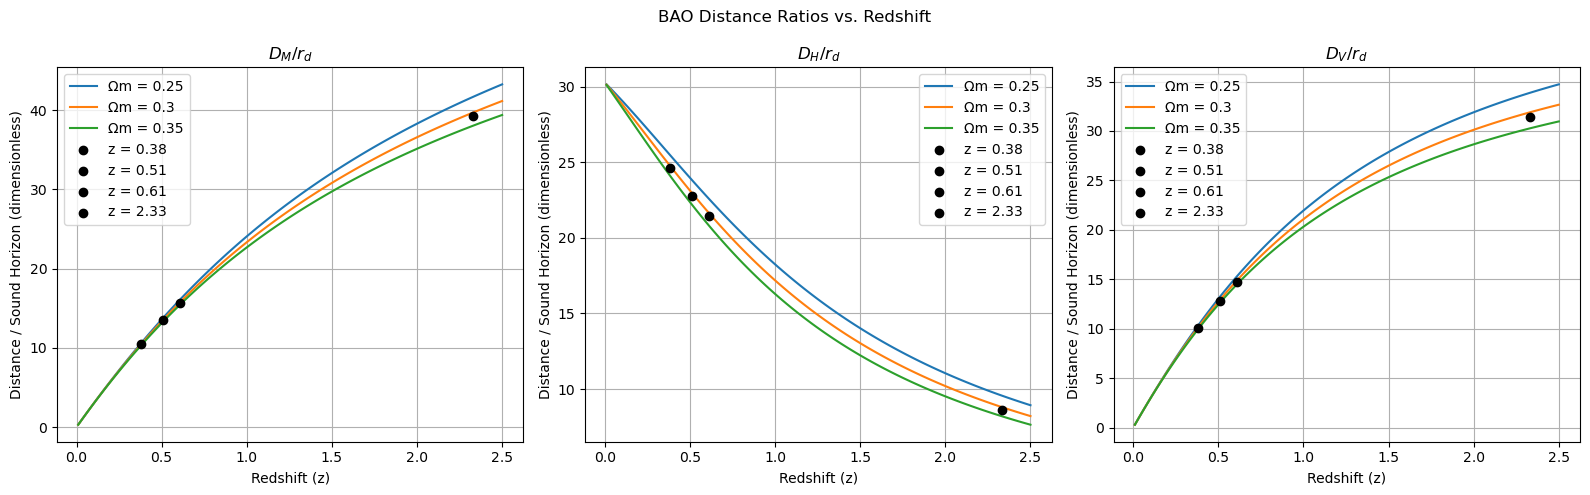

In [5]:
# setting redshift range
z_values = np.linspace(0.01, 2.5, 100)

# setting three matter density values
omega_values = [0.25, 0.30, 0.35]

# creating three plots
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# looping through each matter density value
for omega in omega_values:

    # calculating distance ratios
    DM_values = [D_M(z, hubble_const, omega) / r_d for z in z_values]
    DH_values = [D_H(z, hubble_const, omega) / r_d for z in z_values]
    DV_values = [D_V(z, hubble_const, omega) / r_d for z in z_values]

    # plotting each distance ratio
    axes[0].plot(z_values, DM_values, label=f'Ωm = {omega}')
    axes[1].plot(z_values, DH_values, label=f'Ωm = {omega}')
    axes[2].plot(z_values, DV_values, label=f'Ωm = {omega}')

# setting redshifts for BOSS and Lyman-alpha BAO
marker_redshifts = [0.38, 0.51, 0.61, 2.33]

# looping through each plot
for ax, distance_function in zip(axes, [D_M, D_H, D_V]):

    # adding markers at the two redshifts
    for z_marker in marker_redshifts:

        # calculating distance ratio for reference cosmology
        distance = distance_function(z_marker, hubble_const, omega_m) / r_d

        # plotting the marker
        ax.scatter(z_marker, distance, color='black', marker='o', zorder=5, label=f'z = {z_marker}')

    # labeling axes
    ax.set_xlabel('Redshift (z)')
    ax.set_ylabel('Distance / Sound Horizon (dimensionless)')

    # adding grid and legend
    ax.grid(True)
    ax.legend()

# adding plot titles
axes[0].set_title(r'$D_M/r_d$')
axes[1].set_title(r'$D_H/r_d$')
axes[2].set_title(r'$D_V/r_d$')

# adding overall title
fig.suptitle('BAO Distance Ratios vs. Redshift')

# adjusting spacing
plt.tight_layout()

# displaying plots
plt.show()


**Caption:** 

### Plot 2: Delta theta(z) and Delta z(z)

In [6]:
# your code here

**Caption:** 

### Plot 3: Toy r^2 xi(r)

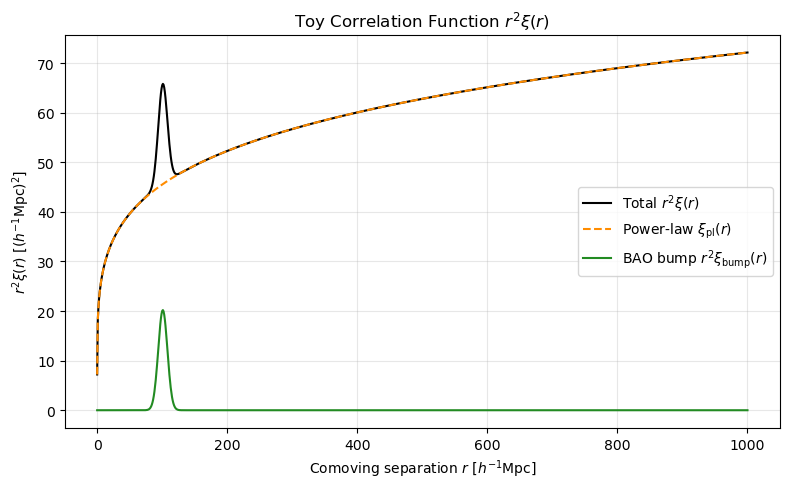

In [7]:
# Grid of r values up to r_max
r_vals = np.linspace(r_min, r_max, 1000)

# Evaluate model components using xi_model
xi_total = xi_model(r_vals, A, gamma, B, r_bao, sigma)
xi_smooth = xi_model(r_vals, A, gamma, 0, r_bao, sigma)
xi_bump = B * np.exp(-((r_vals - r_bao) ** 2) / (sigma**2))

# Plot r^2 * xi(r)
plt.figure(figsize=(8, 5))
plt.plot(r_vals, (r_vals**2) * xi_total, label=r'Total $r^2\xi(r)$', color='black')
plt.plot(r_vals, (r_vals**2) * xi_smooth, label=r'Power-law $\xi_{\mathrm{pl}}(r)$', color='darkorange', linestyle='--')
plt.plot(r_vals, (r_vals**2) * xi_bump, label=r'BAO bump $r^2\xi_{\mathrm{bump}}(r)$', color='forestgreen')

plt.xlabel(r'Comoving separation $r$ [$h^{-1}\mathrm{Mpc}$]')
plt.ylabel(r'$r^2 \xi(r)$ [$(h^{-1}\mathrm{Mpc})^2$]')
plt.title(r'Toy Correlation Function $r^2 \xi(r)$')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

**Caption:** 

### Plot 4: P(k) with and without the bump, vs. the analytic approximation

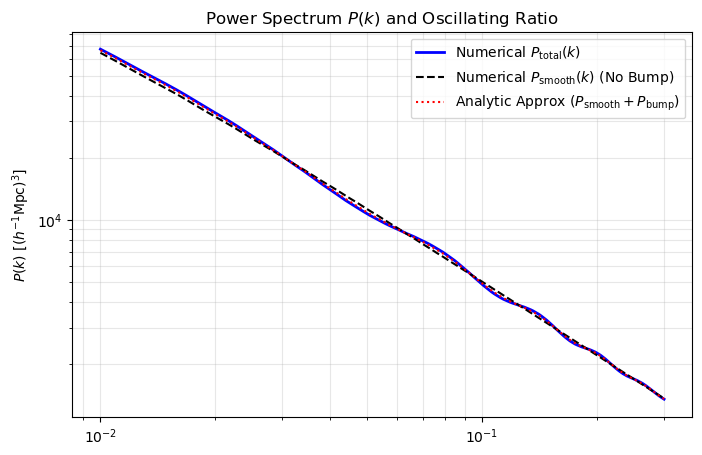

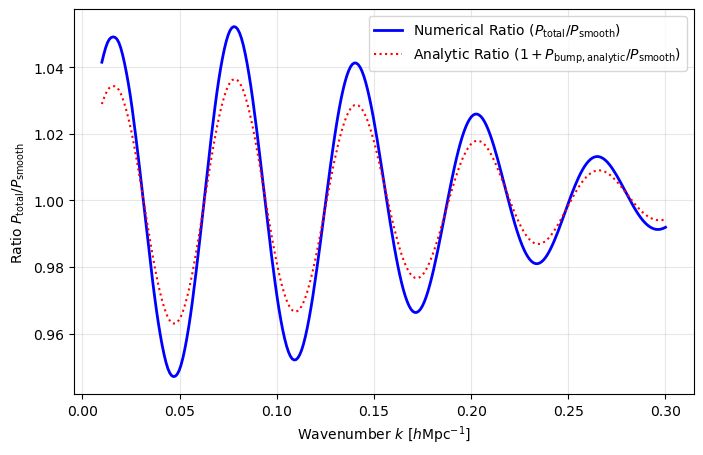

In [12]:
# Wavenumber range
k_vals = np.linspace(0.01,0.3, 300)


# Numerical power spectra integrations (passing A = 0.01)
P_total_num = P_ofk(xi_model, k_vals, A, gamma, B,
                    r_bao, sigma, r_taper, r_min, r_max)
P_smooth_num = P_ofk(xi_smooth_func, k_vals, A, gamma, B,
                     r_bao, sigma, r_taper, r_min, r_max)

# Analytic approximation of BAO bump
P_bump_analytic = (2.0 * np.pi**1.5 * B * sigma * r_bao / k_vals) * np.exp(-(k_vals**2 * sigma**2) / 4.0) * np.sin(k_vals * r_bao)
P_total_analytic = P_smooth_num + P_bump_analytic

# Oscillating ratio
ratio_num = P_total_num / P_smooth_num
ratio_analytic = P_total_analytic / P_smooth_num

# Log-Log Power Spectrum Comparison
fig, ax = plt.subplots(figsize=(8, 5))
ax.loglog(k_vals, P_total_num, label=r'Numerical $P_{\mathrm{total}}(k)$', color='blue', lw=2)
ax.loglog(k_vals, P_smooth_num, label=r'Numerical $P_{\mathrm{smooth}}(k)$ (No Bump)', color='black', linestyle='--')
ax.loglog(k_vals, P_total_analytic, label=r'Analytic Approx ($P_{\mathrm{smooth}} + P_{\mathrm{bump}}$)', color='red', linestyle=':')
ax.set_ylabel(r'$P(k)$ [$(h^{-1}\mathrm{Mpc})^3$]')
ax.set_title(r'Power Spectrum $P(k)$')
ax.grid(True, which='both', alpha=0.3)
ax.legend()
plt.show()

# Oscillating Ratio
fig, ax = plt.subplots(figsize=(8, 5))
plt.plot(k_vals, ratio_num, label=r'Numerical Ratio ($P_{\mathrm{total}} / P_{\mathrm{smooth}}$)', color='blue', lw=2)
plt.plot(k_vals, ratio_analytic, label=r'Analytic Ratio ($1 + P_{\mathrm{bump, analytic}} / P_{\mathrm{smooth}}$)', color='red', linestyle=':')
plt.xlabel(r'Wavenumber $k$ [$h\mathrm{Mpc}^{-1}$]')
plt.ylabel(r'Ratio $P_{\mathrm{total}} / P_{\mathrm{smooth}}$')
plt.title('Oscillating Rati
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

**Caption:** 

## Validation
*Run each check listed on your topic page; report what you found, including failures and what you did about them. The `check` helper below prints PASS or FAIL; use it or `np.isclose`/`assert`.*

In [ ]:
def check(name, value, expected, rtol=1e-2, atol=0.0):
    """Print PASS/FAIL comparing value with expected (relative tolerance rtol)."""
    ok = np.isclose(value, expected, rtol=rtol, atol=atol)
    print(f"{'PASS' if ok else 'FAIL'}  {name}: got {value:.6g}, expected {expected:.6g}")
    return ok

# Example of use (replace with your own checks):
# check("name of check", your_function(args), value_from_topic_page, rtol=3e-3)

### Check 1: Table of D_M/r_d, D_H/r_d, D_V/r_d, Delta theta, Delta z at the listed redshifts

In [ ]:
# your check here

### Check 2: D_V/r_d at z = 0.51 for three Omega_m

In [ ]:
# your check here

### Check 3: Analytic P_bump(k) vs. your transform

In [ ]:
# your check here

## Discussion
*(At most one page: what do the plots tell you physically? Which parameters matter most? What can and cannot Part 3 data constrain?)*

## Extension section(s)
*Extensions: 1 for a group of 2, both for a group of 3 (solo: none). Keep one labeled section per Extension you do, and delete the others.*

### Extension 1: Compute r_d yourself

In [ ]:
# your code here

### Extension 2: Bias in the measured peak position

In [ ]:
# your code here

## Appendix A: AI usage
*Required even if you used none (say so). For each use: the tool, what you asked, what you used, how you verified it. If your use was substantial, add the Verification subsection described in Common Instructions section 6.*

### Verification (substantial use only)

## Appendix B: References

## Changes since Part 2 (leave blank until Part 3)
*In Part 3, keep all of the material above and describe here what you changed and why.*